# TSM-CAM: Improved QAOA

Fix Phnom Penh as departure, encode three destinations with **9 qubits**, normalize distances, and use **p = 2** with **1,024 shots**. Select only valid tours measured in final sampling; no optimizer-best fallback or classical replacement. Aer is noiseless. QAOA remains approximate.


In [78]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# When saved in tsm-cam, the current directory or its parent is detected.
# Change PROJECT_ROOT manually if your project is somewhere else.
search_roots = [Path.cwd(), *Path.cwd().parents,
                Path('/Users/nak/CADT/projects/tsm-cam')]
PROJECT_ROOT = next((p for p in search_roots
                     if (p / 'app/quantum/qaoa.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Set PROJECT_ROOT to your tsm-cam directory.')
sys.path.insert(0, str(PROJECT_ROOT))

from app.classical.locations import build_straight_distance_matrix


plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})
NAVY, TEAL, PURPLE = '#08134d', '#008c95', '#8046e8'
print('Project:', PROJECT_ROOT)


Project: /Users/nak/CADT/projects/tsm-cam


## 1. Read locations and resolve coordinates

Load the departure and destinations with their coordinates. Nodes represent cities; connections are straight lines.

0: Phnom Penh: lat=11.57, lon=104.92
1: Takeo: lat=10.99, lon=104.78
2: Kampong Cham: lat=11.99, lon=105.46
3: Siem Reap: lat=13.36, lon=103.86


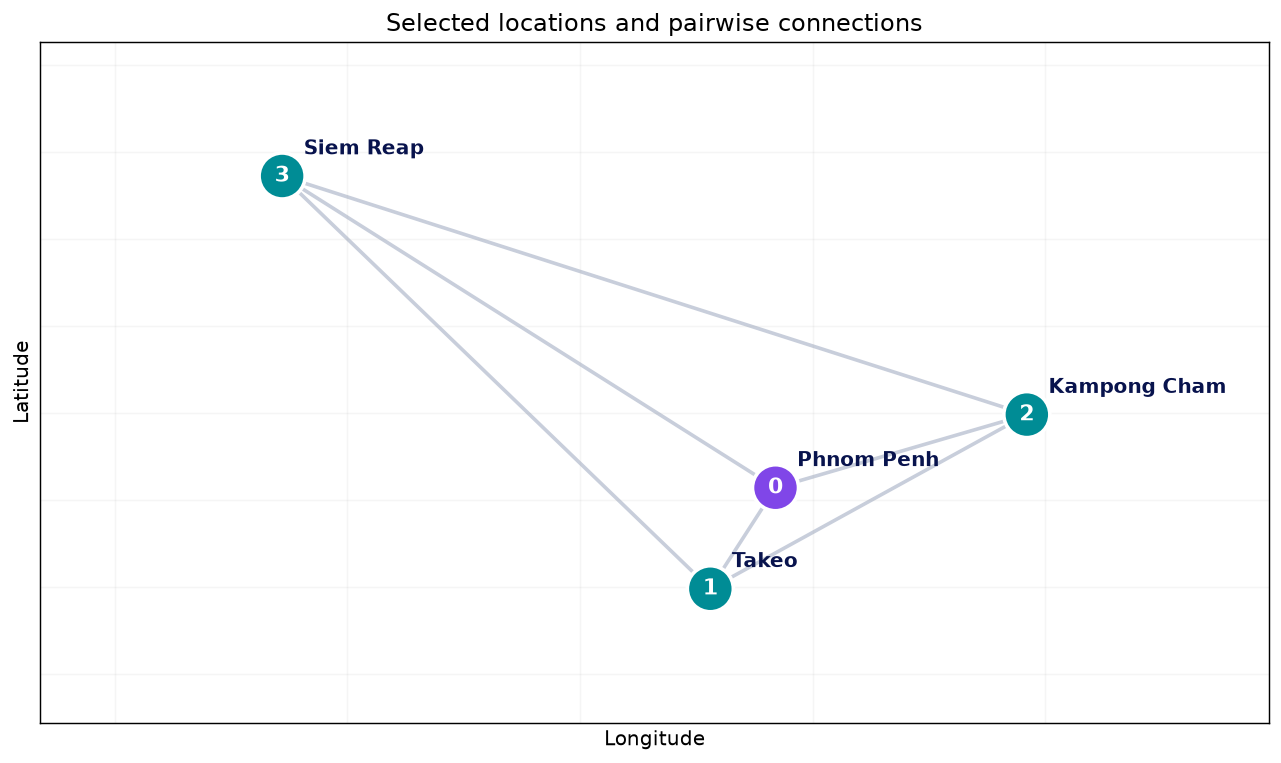

In [79]:
CITY_NAMES = ['Phnom Penh', 'Takeo', 'Kampong Cham', 'Siem Reap']
province_pins = json.loads((PROJECT_ROOT / 'static/data/provinces.json').read_text())
by_name = {p['name'].casefold(): p for p in province_pins}
assert 2 <= len(CITY_NAMES) <= 4, 'Select departure plus 1–3 destinations.'
assert len(set(n.casefold() for n in CITY_NAMES)) == len(CITY_NAMES)
locations = [dict(by_name[name.casefold()]) for name in CITY_NAMES]
n = len(locations)
for i, location in enumerate(locations):
    print(f"{i}: {location['name']}: lat={location['latitude']}, lon={location['longitude']}")

positions = {i: (p['longitude'], p['latitude']) for i, p in enumerate(locations)}
node_colors = [PURPLE if i == 0 else TEAL for i in range(n)]
fig, ax = plt.subplots(figsize=(10, 6))
graph = nx.complete_graph(n)
nx.draw_networkx_edges(graph, positions, ax=ax, edge_color='#c8cedb', width=2)
nx.draw_networkx_nodes(graph, positions, ax=ax, node_color=node_colors,
                       node_size=650, edgecolors='white', linewidths=2)
nx.draw_networkx_labels(graph, positions, labels={i: str(i) for i in range(n)},
                        ax=ax, font_color='white', font_weight='bold')
for i, (lon, lat) in positions.items():
    ax.annotate(locations[i]['name'], (lon, lat), xytext=(12, 12),
                textcoords='offset points', color=NAVY, fontweight='bold')
ax.set(xlabel='Longitude', ylabel='Latitude',
       title='Selected locations and pairwise connections')
ax.margins(0.25)
ax.grid(alpha=0.12)
plt.tight_layout()
plt.show()


## 2. Calculate distances and build the matrix

Calculate pairwise Haversine distances. Each matrix entry is a distance in kilometers.

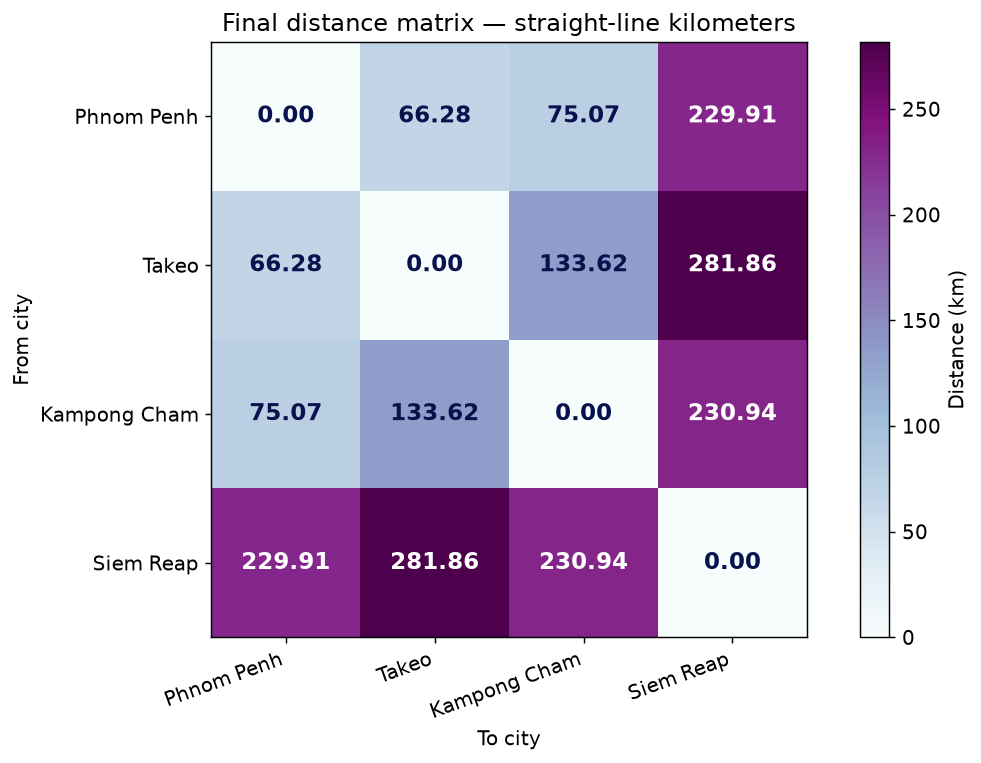

Numeric matrix passed to the TSP model:
[[  0.    66.28  75.07 229.91]
 [ 66.28   0.   133.62 281.86]
 [ 75.07 133.62   0.   230.94]
 [229.91 281.86 230.94   0.  ]]


In [80]:
matrix_data = build_straight_distance_matrix(locations)
distance_matrix = np.asarray(matrix_data['distances'], dtype=float)
assert distance_matrix.shape == (n, n)
assert np.allclose(distance_matrix, distance_matrix.T)
assert np.allclose(np.diag(distance_matrix), 0)

fig, ax = plt.subplots(figsize=(9, 6))
heatmap = ax.imshow(distance_matrix, cmap='BuPu', vmin=0)
ax.set_xticks(range(n), CITY_NAMES, rotation=20, ha='right')
ax.set_yticks(range(n), CITY_NAMES)
ax.set(xlabel='To city', ylabel='From city',
       title='Final distance matrix — straight-line kilometers')
for i in range(n):
    for j in range(n):
        color = 'white' if distance_matrix[i, j] > distance_matrix.max() * 0.6 else NAVY
        ax.text(j, i, f'{distance_matrix[i, j]:.2f}', ha='center', va='center',
                color=color, fontsize=13, fontweight='bold')
fig.colorbar(heatmap, ax=ax, label='Distance (km)')
plt.tight_layout()
plt.show()
print('Numeric matrix passed to the TSP model:')
print(np.array2string(distance_matrix, precision=2, suppress_small=True))


In [81]:
def route_names(tour):
    return ' → '.join(CITY_NAMES[i] for i in tour)

def tour_distance(tour):
    return float(sum(distance_matrix[a, b] for a, b in zip(tour, tour[1:])))



## 3. Encode the route (classical)
Phnom Penh is fixed outside the binary assignment. Three destinations × three positions need **9 qubits**. Set `RETURN_TO_START = False` for an open route. Normalized distances and a penalty of 4 keep the objective well scaled; reported distances remain kilometers.

In [82]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.translators import to_ising

RETURN_TO_START = True  # False: stop at the last destination.
m = n - 1
DISTANCE_SCALE = float(distance_matrix.max())
weights = distance_matrix / DISTANCE_SCALE
problem = QuadraticProgram('Route with fixed departure')
for city in range(m):
    for position in range(m):
        problem.binary_var(name=f'x_{city}_{position}')

# x_city_position now represents destination city+1, not Phnom Penh.
linear = {}
quadratic = {}
for city in range(m):
    linear[f'x_{city}_0'] = float(weights[0, city+1])
    if RETURN_TO_START:
        key = f'x_{city}_{m-1}'
        linear[key] = linear.get(key, 0.0) + float(weights[city+1, 0])
for position in range(m-1):
    for a in range(m):
        for b in range(m):
            if a != b:
                quadratic[(f'x_{a}_{position}', f'x_{b}_{position+1}')] = float(weights[a+1,b+1])
problem.minimize(linear=linear, quadratic=quadratic)
for city in range(m):
    problem.linear_constraint({f'x_{city}_{p}': 1 for p in range(m)}, '==', 1, f'city_{city}')
for position in range(m):
    problem.linear_constraint({f'x_{city}_{position}': 1 for city in range(m)}, '==', 1, f'position_{position}')

# A valid normalized route costs at most n (each leg <= 1).
# A non-permutation breaks at least two row/column constraints, costing >= 2*n.
PENALTY = float(n)
qubo = QuadraticProgramToQubo(penalty=PENALTY).convert(problem)
hamiltonian, offset = to_ising(qubo)
weighted_graph = nx.from_numpy_array(distance_matrix)
print('Return to Phnom Penh:', RETURN_TO_START)
print('Qubits:', hamiltonian.num_qubits, '| Pauli terms:', len(hamiltonian.paulis))
print('Distance scale (km):', round(DISTANCE_SCALE, 2), '| Penalty:', PENALTY)

Return to Phnom Penh: True
Qubits: 9 | Pauli terms: 39
Distance scale (km): 281.86 | Penalty: 4.0


## 4. Quantum processing
Use the Step 3 Hamiltonian. COBYLA tunes the angles; final measurement uses fixed 1,024 shots.

### 4.1 Configure QAOA
Use two layers and allow up to 100 COBYLA evaluations. Each evaluation and final sampling use 1,024 shots.

In [83]:
from qiskit import transpile
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.minimum_eigensolvers import QAOA

SHOTS = 1024
SEED = 42
P = 2
MAXITER = 100
backend = AerSimulator(max_parallel_threads=4)
pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
sampler = SamplerV2(default_shots=SHOTS, seed=SEED,
    options={'backend_options': {'max_parallel_threads': 4}})
# Parameter order: beta_0, beta_1, gamma_0, gamma_1.
initial_angles = np.full(2*P, 0.2)
print(f'{hamiltonian.num_qubits} qubits | p={P} | {SHOTS} shots per evaluation and final sampling')

9 qubits | p=2 | 1024 shots per evaluation and final sampling


### 4.2 Optimize angles
Optimize sampled mean energy, which includes penalties and is not a distance. No exact solution or route is supplied to QAOA.

Optimized parameters: [0.21329425 1.20473748 0.18079395 0.15733853]
Objective evaluations: 31


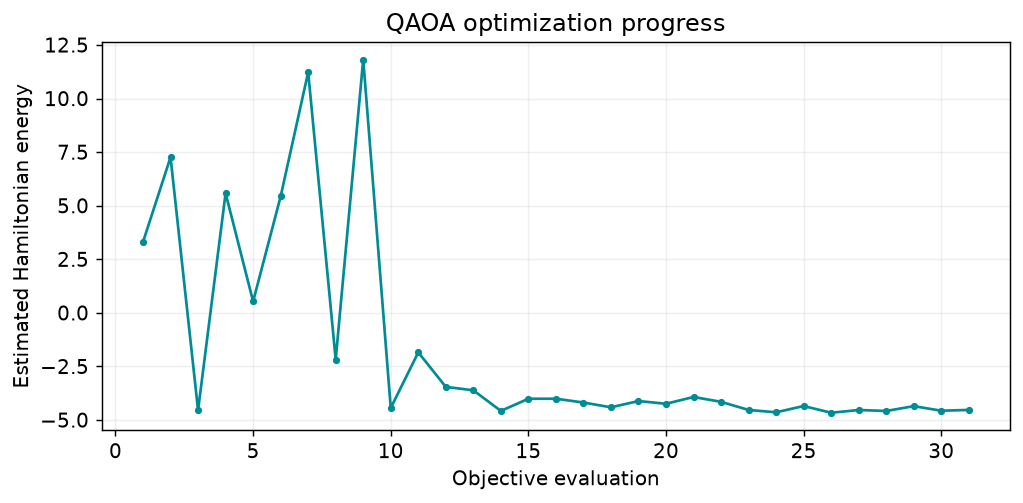

In [84]:
optimization_log = []
def record_evaluation(evaluation, parameters, mean, metadata):
    optimization_log.append((int(evaluation), float(np.real(mean))))

qaoa = QAOA(sampler=sampler, optimizer=COBYLA(maxiter=MAXITER, tol=1e-3),
    reps=P, pass_manager=pass_manager, initial_point=initial_angles, callback=record_evaluation)
qaoa_result = qaoa.compute_minimum_eigenvalue(hamiltonian)
print('Optimized parameters:', qaoa_result.optimal_point)
print('Objective evaluations:', len(optimization_log))
evaluations, energies = zip(*optimization_log)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(evaluations, energies, 'o-', color=TEAL, markersize=3)
ax.set(xlabel='Objective evaluation', ylabel='Estimated Hamiltonian energy', title='QAOA optimization progress')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

### 4.3 Final measurement
Run the optimized circuit for 1,024 shots. Every histogram bar is an actual measured count.

In [85]:
circuit = qaoa.ansatz.remove_final_measurements(inplace=False)
circuit = circuit.assign_parameters(qaoa_result.optimal_point)
circuit.measure_all()
compiled = transpile(circuit, backend, seed_transpiler=SEED)
counts = backend.run(compiled, shots=SHOTS, seed_simulator=SEED).result().get_counts()
assert sum(counts.values()) == SHOTS
print('Final shots:', sum(counts.values()), '| Unique bitstrings:', len(counts))

Final shots: 1024 | Unique bitstrings: 321


### 4.4 Decode and validate (classical)
Decode the 3×3 destination assignment, add Phnom Penh at the start, and optionally append its return. Keep only valid final measurements; do not repair invalid bitstrings or add earlier optimizer samples.

Valid final shots: 152/1024 (14.84%)
Unique valid candidates: 6
654.16 km | 22 shots | Phnom Penh → Kampong Cham → Siem Reap → Takeo → Phnom Penh
654.16 km | 26 shots | Phnom Penh → Takeo → Siem Reap → Kampong Cham → Phnom Penh
660.75 km | 27 shots | Phnom Penh → Siem Reap → Kampong Cham → Takeo → Phnom Penh
660.75 km | 33 shots | Phnom Penh → Takeo → Kampong Cham → Siem Reap → Phnom Penh
720.47 km | 24 shots | Phnom Penh → Kampong Cham → Takeo → Siem Reap → Phnom Penh
720.47 km | 20 shots | Phnom Penh → Siem Reap → Takeo → Kampong Cham → Phnom Penh


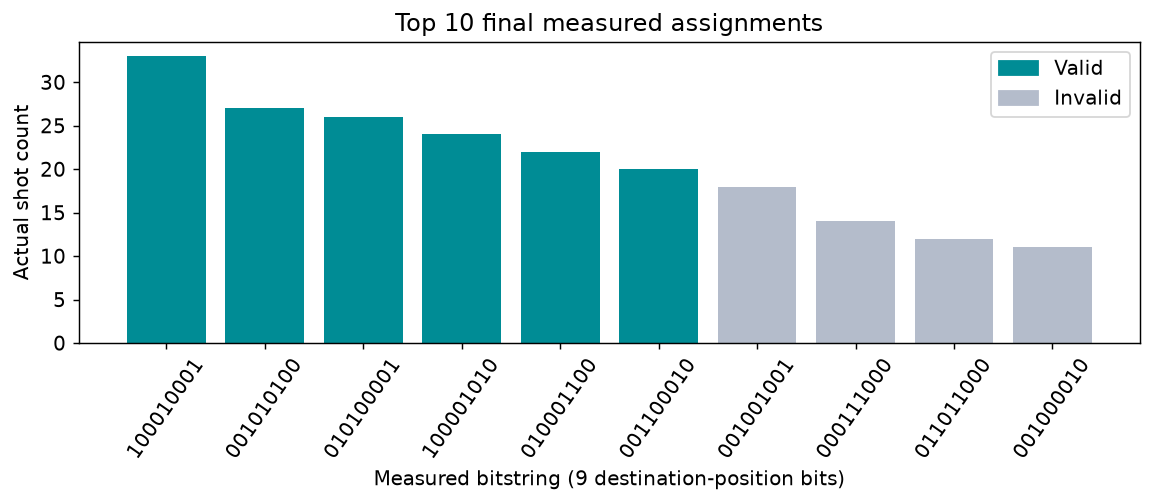

In [86]:
def decode_tour(bitstring):
    assignment = np.array([int(bit) for bit in bitstring[::-1]]).reshape(m,m)
    if not (np.all(assignment.sum(axis=0)==1) and np.all(assignment.sum(axis=1)==1)):
        return None
    destinations = [int(np.argmax(assignment[:,p]))+1 for p in range(m)]
    return [0, *destinations] + ([0] if RETURN_TO_START else [])

candidates = []
valid_shots = 0
for bits, count in counts.items():
    tour = decode_tour(bits)
    if tour is not None:
        valid_shots += count
        candidates.append({'tour':tour, 'bitstring':bits, 'count':count})
print(f'Valid final shots: {valid_shots}/{SHOTS} ({100*valid_shots/SHOTS:.2f}%)')
print('Unique valid candidates:', len(candidates))
for candidate in sorted(candidates,key=lambda c:tour_distance(c['tour'])):
    print(f"{tour_distance(candidate['tour']):.2f} km | {candidate['count']} shots | {route_names(candidate['tour'])}")

from matplotlib.patches import Patch
top_counts = sorted(counts.items(), key=lambda item:item[1], reverse=True)[:10]
fig, ax = plt.subplots(figsize=(9,4))
ax.bar([bits for bits,count in top_counts], [count for bits,count in top_counts],
    color=[TEAL if decode_tour(bits) is not None else '#b4bccb' for bits,count in top_counts])
ax.set(xlabel='Measured bitstring (9 destination-position bits)', ylabel='Actual shot count',
       title='Top 10 final measured assignments')
ax.tick_params(axis='x',rotation=55)
ax.legend(handles=[Patch(color=TEAL,label='Valid'),Patch(color='#b4bccb',label='Invalid')])
plt.tight_layout()
plt.show()

## 5. Select and visualize (classical)
Choose the shortest valid final-sample candidate. Add the fixed Phnom Penh row and position only for the full route display.

Selected route: Phnom Penh → Kampong Cham → Siem Reap → Takeo → Phnom Penh
Distance: 654.16 km | Final count: 22
Measured 9-bit assignment: 010001100


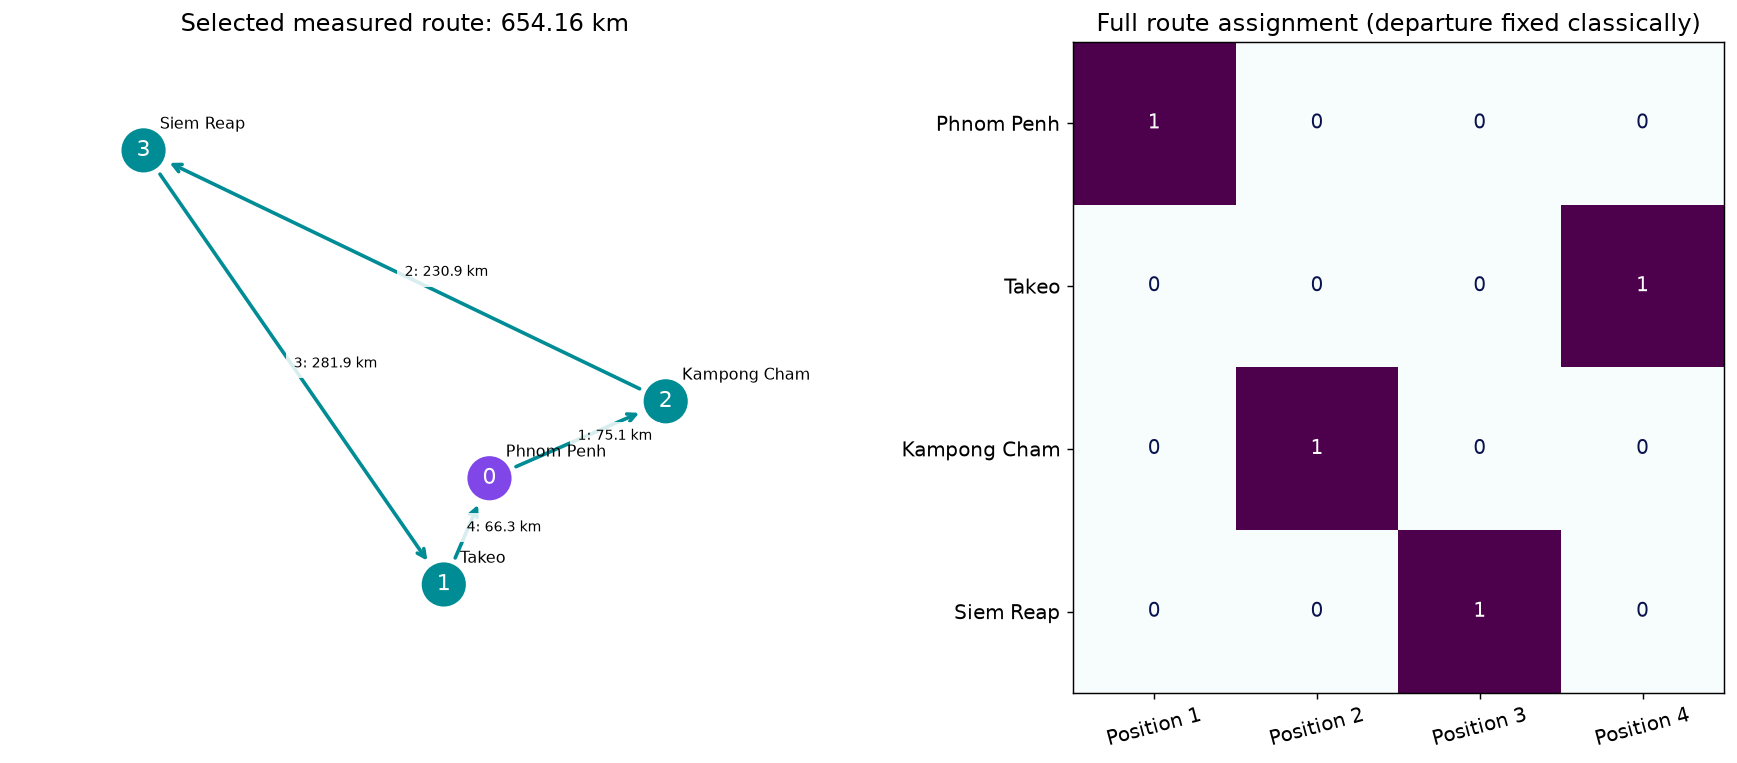

In [87]:
selected = None
if candidates:
    selected = min(candidates,key=lambda c:tour_distance(c['tour']))
    selected_tour = selected['tour']
    selected_distance = tour_distance(selected_tour)
    print('Selected route:',route_names(selected_tour))
    print(f'Distance: {selected_distance:.2f} km | Final count: {selected["count"]}')
    print('Measured 9-bit assignment:',selected['bitstring'])
    assignment = np.zeros((n,n),dtype=int)
    cities = selected_tour[:-1] if RETURN_TO_START else selected_tour
    for position,city in enumerate(cities):
        assignment[city,position]=1
    assert np.all(assignment.sum(0)==1) and np.all(assignment.sum(1)==1)
    fig,(ax,grid_ax)=plt.subplots(1,2,figsize=(14,6))
    nx.draw_networkx_nodes(weighted_graph,positions,ax=ax,node_color=node_colors,node_size=550)
    nx.draw_networkx_labels(weighted_graph,positions,ax=ax,font_color='white')
    for step,(a,b) in enumerate(zip(selected_tour,selected_tour[1:]),1):
        ax.annotate('',xy=positions[b],xytext=positions[a],
            arrowprops={'arrowstyle':'->','color':TEAL,'lw':2,'shrinkA':16,'shrinkB':16})
        midpoint=(np.array(positions[a])+np.array(positions[b]))/2
        ax.text(*midpoint,f'{step}: {distance_matrix[a,b]:.1f} km',fontsize=8,
            bbox={'facecolor':'white','edgecolor':'none','alpha':.85})
    for i,point in positions.items():
        ax.annotate(CITY_NAMES[i],point,xytext=(9,12),textcoords='offset points',fontsize=9)
    ax.margins(.25)
    ax.set_axis_off()
    ax.set_title(f'Selected measured route: {selected_distance:.2f} km')
    grid_ax.imshow(assignment,cmap='BuPu',vmin=0,vmax=1)
    grid_ax.set_xticks(range(n),[f'Position {p+1}' for p in range(n)],rotation=15)
    grid_ax.set_yticks(range(n),CITY_NAMES)
    grid_ax.set_title('Full route assignment (departure fixed classically)')
    for i in range(n):
        for p in range(n):
            grid_ax.text(p,i,str(assignment[i,p]),ha='center',va='center',
                color='white' if assignment[i,p] else NAVY)
    plt.tight_layout()
    plt.show()
else:
    print('No valid final candidate: report failure rather than substitute a classical route.')

## Separate benchmark and encoding checks
Only after measurement, enumerate the six destination orders to check quality. The benchmark never supplies candidates to QAOA. Matching this tiny benchmark is not evidence of quantum speedup.

In [88]:
from itertools import permutations
benchmark_routes = [[0,*order]+([0] if RETURN_TO_START else [])
                    for order in permutations(range(1,n))]
classical_best = min(benchmark_routes,key=tour_distance)
classical_distance = tour_distance(classical_best)
# Check the modeled objective and binary decoder against all valid orders.
for route in benchmark_routes:
    destinations = route[1:-1] if RETURN_TO_START else route[1:]
    bits = np.zeros((m,m),dtype=int)
    for position,city in enumerate(destinations):bits[city-1,position]=1
    assert problem.is_feasible(bits.reshape(-1))
    assert np.isclose(problem.objective.evaluate(bits.reshape(-1))*DISTANCE_SCALE,tour_distance(route))
    assert np.isclose(qubo.objective.evaluate(bits.reshape(-1))*DISTANCE_SCALE,tour_distance(route))
    assert decode_tour(''.join(str(x) for x in bits.reshape(-1)[::-1])) == route
print('Encoding checks passed for all six valid orders.')
print('Exact route:',route_names(classical_best))
print(f'Exact distance: {classical_distance:.2f} km')
if selected is not None:
    gap=100*(selected_distance-classical_distance)/classical_distance
    print(f'Selected QAOA gap: {gap:.2f}%')
    print('Matches exact minimum:',bool(np.isclose(selected_distance,classical_distance)))

Encoding checks passed for all six valid orders.
Exact route: Phnom Penh → Kampong Cham → Siem Reap → Takeo → Phnom Penh
Exact distance: 654.16 km
Selected QAOA gap: 0.00%
Matches exact minimum: True


## Reference and limits
The [reference repository](https://github.com/codeWithUtkarsh/tsp-quantum-algorithm) discusses distance/penalty weighting, QAOA depth and COBYLA budgets. This notebook is an independently built fixed-departure formulation, not a reproduction of its custom Hamiltonian. The repository README and checked configuration differ on depth and shots; its core processing file could not be retrieved during this review.

The separate `scripts/validate_qaoa_improvements.py` experiment checks both 16- and 9-qubit normalized models on five seeds for open and closed routes, with results in `docs/qaoa_improvement_trials.json`. Per-evaluation shots stay fixed, but deeper circuits and a larger evaluation budget change total compute cost. Neither sampled selection nor a handful of successful seeds guarantees success on new instances.